# 01 - Data Analysis
It loads, validates, and explores the traffic dataset. The cleaning logic comes from backend/preprocessing.py.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from backend import preprocessing as pp, model as tm

In [2]:
raw = pp.load_raw()
raw.head()

,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041


In [3]:
clean_df, report = pp.clean(raw)
report

{'rows_in': 48120,
 'missing_values': 0,
 'unparseable_datetimes': 0,
 'duplicates_dropped': 0,
 'duplicate_ids': 0,
 'hourly_gaps': 0,
 'rows_out': 48120,
 'rows_per_junction': {1: 14592, 2: 14592, 3: 14592, 4: 4344},
 'junction_first_record': {1: '2015-11-01 00:00:00',
  2: '2015-11-01 00:00:00',
  3: '2015-11-01 00:00:00',
  4: '2017-01-01 00:00:00'},
 'junction_last_record': {1: '2017-06-30 23:00:00',
  2: '2017-06-30 23:00:00',
  3: '2017-06-30 23:00:00',
  4: '2017-06-30 23:00:00'}}

In [4]:
clean_df.describe()

,ID,DateTime,Junction,Vehicles
count,4.812000e+04,48120,48120.000000,48120.000000
mean,2.016330e+10,2016-09-19 06:03:56.109725,2.180549,22.791334
min,2.015110e+10,2015-11-01 00:00:00,1.000000,1.000000
25%,2.016042e+10,2016-04-16 01:45:00,1.000000,9.000000
50%,2.016093e+10,2016-09-30 03:30:00,2.000000,15.000000
75%,2.017023e+10,2017-02-25 16:00:00,3.000000,29.000000
max,2.017063e+10,2017-06-30 23:00:00,4.000000,180.000000
std,5.944854e+06,NaN,0.966955,20.750063


## Junction-wise traffic

In [5]:
clean_df.groupby('Junction')['Vehicles'].agg(['count','mean','std','min','max'])

,count,mean,std,min,max
Junction,,,,,
1,14592,45.052906,23.008345,5,156
2,14592,14.253221,7.401307,1,48
3,14592,13.694010,10.436005,1,180
4,4344,7.251611,3.521455,1,36


## Hourly pattern (peak hours)

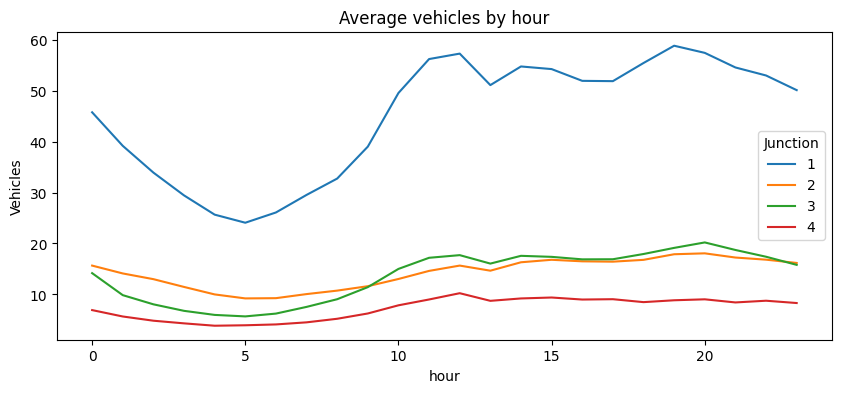

In [6]:
hourly = clean_df.assign(hour=clean_df.DateTime.dt.hour).groupby(['hour','Junction'])['Vehicles'].mean().unstack()
hourly.plot(figsize=(10,4), title='Average vehicles by hour')
plt.ylabel('Vehicles'); plt.show()

## Weekday pattern

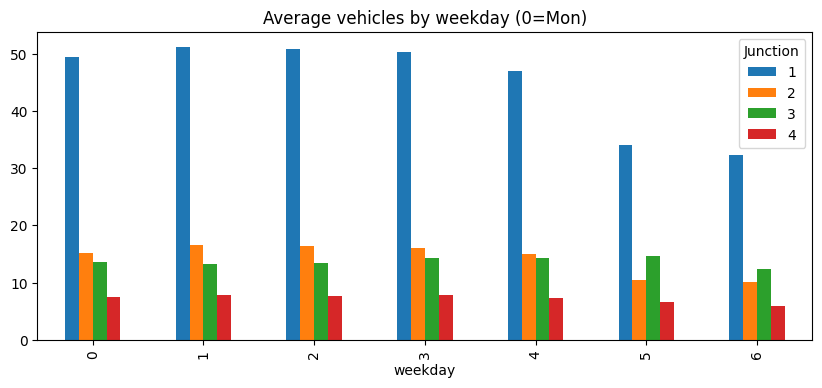

In [7]:
wk = clean_df.assign(weekday=clean_df.DateTime.dt.dayofweek).groupby(['weekday','Junction'])['Vehicles'].mean().unstack()
wk.plot(kind='bar', figsize=(10,4), title='Average vehicles by weekday (0=Mon)')
plt.show()

## Feature engineering aur processed data save

In [8]:
features = pp.build_features(clean_df)
print(features.shape)
features.head()

(47448, 16)


,ID,DateTime,Junction,Vehicles,hour,day,month,weekday,is_weekend,lag_1,lag_2,lag_3,lag_24,lag_168,roll_mean_3,roll_mean_24
0,20151108001,2015-11-08 00:00:00,1,13,0,8,11,6,1,15.0,16.0,17.0,16.0,15.0,16.000000,13.125000
1,20151108011,2015-11-08 01:00:00,1,16,1,8,11,6,1,13.0,15.0,16.0,16.0,13.0,14.666667,13.000000
2,20151108021,2015-11-08 02:00:00,1,11,2,8,11,6,1,16.0,13.0,15.0,10.0,10.0,14.666667,13.000000
3,20151108031,2015-11-08 03:00:00,1,8,3,8,11,6,1,11.0,16.0,13.0,9.0,7.0,13.333333,13.041667
4,20151108041,2015-11-08 04:00:00,1,10,4,8,11,6,1,8.0,11.0,16.0,8.0,9.0,11.666667,13.000000


In [9]:
pp.run_preprocessing()

{'rows_in': 48120,
 'missing_values': 0,
 'unparseable_datetimes': 0,
 'duplicates_dropped': 0,
 'duplicate_ids': 0,
 'hourly_gaps': 0,
 'rows_out': 48120,
 'rows_per_junction': {1: 14592, 2: 14592, 3: 14592, 4: 4344},
 'junction_first_record': {1: '2015-11-01 00:00:00',
  2: '2015-11-01 00:00:00',
  3: '2015-11-01 00:00:00',
  4: '2017-01-01 00:00:00'},
 'junction_last_record': {1: '2017-06-30 23:00:00',
  2: '2017-06-30 23:00:00',
  3: '2017-06-30 23:00:00',
  4: '2017-06-30 23:00:00'},
 'feature_rows': 47448}